In [1]:
!pip install psutil matplotlib pandas -q

import os
import sys
import subprocess
import platform
import torch
import psutil
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")
print("Python Version:", sys.version)
print("Operating System:", platform.system())

Libraries imported successfully!
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Operating System: Linux


In [2]:
import os

project_name = "Session4_Project"

folders = [
    "src",
    "data/raw",
    "data/processed",
    "notebooks",
    "outputs",
    "outputs/graphs",
    "reports",
    "tests"
]

for folder in folders:
    os.makedirs(os.path.join(project_name, folder), exist_ok=True)

print("Project folders created successfully!")

for root, dirs, files in os.walk(project_name):
    level = root.replace(project_name, "").count(os.sep)
    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

Project folders created successfully!
Session4_Project/
    data/
        processed/
        raw/
    reports/
    tests/
    notebooks/
    outputs/
        graphs/
    src/


In [3]:
import os
import subprocess

os.chdir("/content/Session4_Project")

# Initialise Git
subprocess.run(["git", "init"], check=True)

# Create main branch
subprocess.run(["git", "branch", "-M", "main"], check=True)

# Create README file
with open("README.md", "w") as file:
    file.write("# Session 4 Project\n")
    file.write("Repository organisation and environment setup.")

# Create requirements file
with open("requirements.txt", "w") as file:
    file.write("torch\nmatplotlib\npandas\npsutil\n")

# Configure local Git identity for this demonstration
subprocess.run(["git", "config", "user.name", "Student"], check=True)
subprocess.run(["git", "config", "user.email", "student@example.com"], check=True)

# Add and commit files
subprocess.run(["git", "add", "."], check=True)
subprocess.run(
    ["git", "commit", "-m", "Initial project setup"],
    check=True
)

print("Git repository initialised successfully!")
print("Current Branch: main")

subprocess.run(["git", "status", "--short", "--branch"])

Git repository initialised successfully!
Current Branch: main


CompletedProcess(args=['git', 'status', '--short', '--branch'], returncode=0)

In [4]:
print("PYTHON ENVIRONMENT DETAILS")
print("--------------------------")

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("cuDNN Version:", torch.backends.cudnn.version())
else:
    print("GPU not available. Running on CPU.")

print("\nEnvironment check completed!")

PYTHON ENVIRONMENT DETAILS
--------------------------
Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
CUDA Available: False
GPU not available. Running on CPU.

Environment check completed!


In [5]:
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create two matrices
a = torch.rand(1000, 1000, device=device)
b = torch.rand(1000, 1000, device=device)

start_time = time.time()

# Matrix multiplication
result = torch.matmul(a, b)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Device Used:", device)
print("Matrix Shape:", result.shape)
print("GPU Test Successful!")
print("Execution Time:", round(end_time - start_time, 4), "seconds")

Device Used: cpu
Matrix Shape: torch.Size([1000, 1000])
GPU Test Successful!
Execution Time: 0.0669 seconds


In [6]:
import json

environment = {
    "Python Version": platform.python_version(),
    "PyTorch Version": torch.__version__,
    "CUDA Available": torch.cuda.is_available(),
    "CUDA Version": torch.version.cuda,
    "cuDNN Version": torch.backends.cudnn.version(),
    "GPU Name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "Not Available"
    ),
    "Operating System": platform.platform()
}

# Display report
for key, value in environment.items():
    print(key, ":", value)

# Save report
with open("reports/environment_report.json", "w") as file:
    json.dump(environment, file, indent=4)

print("\nEnvironment report saved successfully!")

Python Version : 3.13.18
PyTorch Version : 2.14.1+cpu
CUDA Available : False
CUDA Version : None
cuDNN Version : None
GPU Name : Not Available
Operating System : Linux-6.6.159+-x86_64-with-glibc2.39

Environment report saved successfully!


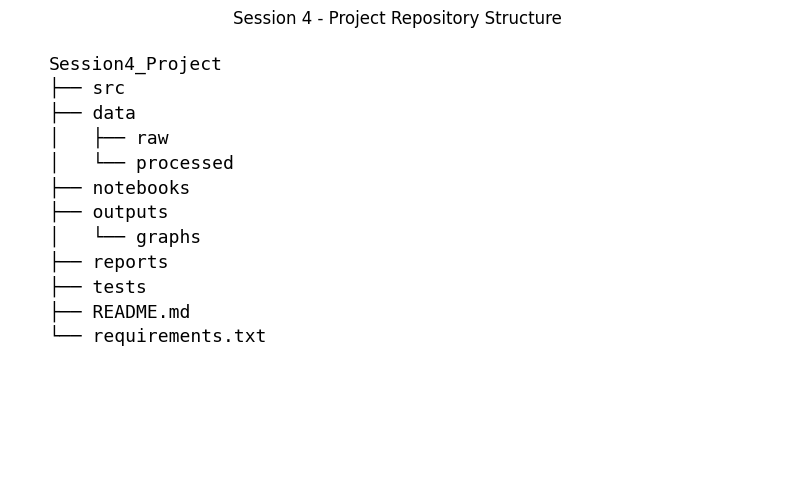

In [7]:
import matplotlib.pyplot as plt

structure = [
    "Session4_Project",
    "├── src",
    "├── data",
    "│   ├── raw",
    "│   └── processed",
    "├── notebooks",
    "├── outputs",
    "│   └── graphs",
    "├── reports",
    "├── tests",
    "├── README.md",
    "└── requirements.txt"
]

plt.figure(figsize=(10, 6))

plt.text(
    0.05, 0.95,
    "\n".join(structure),
    fontsize=13,
    family="monospace",
    verticalalignment="top"
)

plt.title("Session 4 - Project Repository Structure")
plt.axis("off")
plt.show()

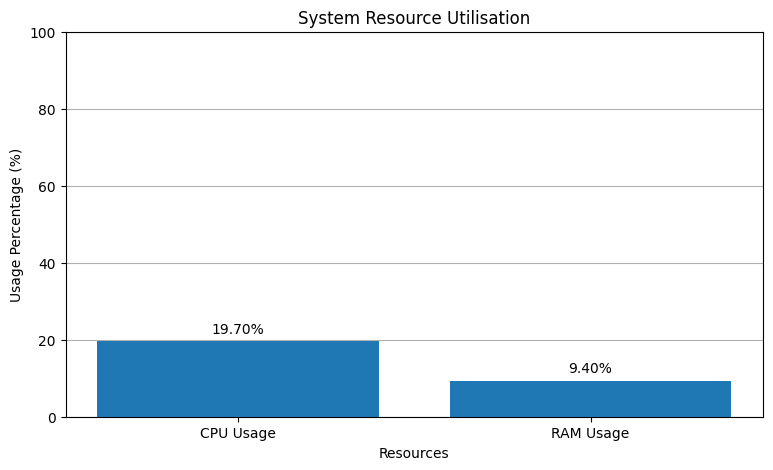

In [8]:
import psutil
import torch
import matplotlib.pyplot as plt

cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

labels = ["CPU Usage", "RAM Usage"]
values = [cpu_usage, ram_usage]

if torch.cuda.is_available():
    total_gpu_memory = torch.cuda.get_device_properties(0).total_memory
    used_gpu_memory = torch.cuda.memory_allocated(0)
    gpu_usage = (used_gpu_memory / total_gpu_memory) * 100

    labels.append("GPU Memory Used")
    values.append(gpu_usage)

plt.figure(figsize=(9, 5))

plt.bar(labels, values)

plt.title("System Resource Utilisation")
plt.xlabel("Resources")
plt.ylabel("Usage Percentage (%)")
plt.ylim(0, 100)
plt.grid(axis="y")

for i, value in enumerate(values):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.show()

       Package Installed Version
0        torch        2.14.1+cpu
1  torchvision        0.29.1+cpu
2   matplotlib            3.10.0
3       pandas             2.2.3
4       psutil             5.9.5


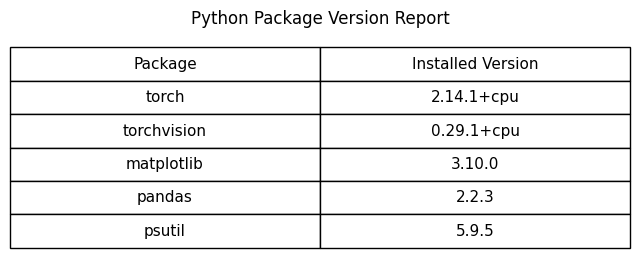

Package version report saved!


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import subprocess
import os

packages = ["torch", "torchvision", "matplotlib", "pandas", "psutil"]

versions = []

for package in packages:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True,
        text=True
    )

    version = "Not installed"

    for line in result.stdout.splitlines():
        if line.startswith("Version:"):
            version = line.split(":", 1)[1].strip()

    versions.append(version)

package_data = pd.DataFrame({
    "Package": packages,
    "Installed Version": versions
})

print(package_data)

# Display as a graphical table
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")

table = ax.table(
    cellText=package_data.values,
    colLabels=package_data.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

plt.title("Python Package Version Report")
plt.show()

# Save package versions
package_data.to_csv("reports/package_versions.csv", index=False)

print("Package version report saved!")

In [10]:
import subprocess
import os

print("SESSION 4 FINAL VERIFICATION")
print("============================")

print("\nProject Folder:")
print(os.getcwd())

print("\nGit Status:")
subprocess.run(["git", "status", "--short", "--branch"])

print("\nProject Files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d != ".git"]

    for file in files:
        print(os.path.join(root, file))

print("\nSession 4 Activity Completed Successfully!")

SESSION 4 FINAL VERIFICATION

Project Folder:
/content/Session4_Project

Git Status:

Project Files:
./requirements.txt
./README.md
./reports/environment_report.json
./reports/package_versions.csv

Session 4 Activity Completed Successfully!
